In [1]:
import illustris_python as il
import numpy as np
import matplotlib.pylab as plt
import os
import h5py
from scipy.stats import binned_statistic

# Paths to the IllustrisTNG catalogues

basePath_TNG50 = '/home/tnguser/sims.TNG/TNG50-2/output/'

#snapshot and redshift we will use
snap = 99
red = 0.0
h = 0.6774

In [2]:
# Subhalo properties we will read. For a full list, see: https://www.tng-project.org/data/docs/specifications/
fields_sub = ['SubhaloStarMetalFractions','SubhaloMass','SubhaloMassType','SubhaloMassInHalfRadType','SubhaloStarMetallicity',
             'SubhaloSFR','SubhaloSFRinRad','SubhaloSFRinHalfRad']

# Read subhalo properties

subhalos_TNG50 = il.groupcat.loadSubhalos(basePath_TNG50, snap, fields=fields_sub)

In [3]:
Mstarsubhalo_TNG50 = subhalos_TNG50['SubhaloMassType'][:,4]*10**10. /h  #Star
Mgassubhalo_TNG50 = subhalos_TNG50['SubhaloMassType'][:,0]*10**10. /h  #Gas
Metallicity_TNG50 = subhalos_TNG50['SubhaloStarMetallicity'] #Metallicity
SFR_TNG50 = subhalos_TNG50['SubhaloSFR']  #SFR
SFRinRad_TNG50 = subhalos_TNG50['SubhaloSFRinRad']    #SFRInRad
SFRinHalfRad_TNG50 = subhalos_TNG50['SubhaloSFRinHalfRad']  #SFRinHalfRad


#mask = (Mstarsubhalo_TNG50 >= minmass) & (Mstarsubhalo_TNG50 <= maxmass)
#Mstarsubhalo_TNG50 = Mstarsubhalo_TNG50[mask]
len(Mstarsubhalo_TNG50)

859077

In [14]:
Mstarsubhalo_TNG50.shape

(859077,)

In [15]:
Mstarsubhalo_TNG50[1]

240346530000.0

/tmp/ipykernel_30/3183646897.py:8: RuntimeWarning: divide by zero encountered in log10
  plt.scatter(np.log10(Mstarsubhalo_TNG50),np.log10(Mgassubhalo_TNG50),s=0.9,c='darkcyan')


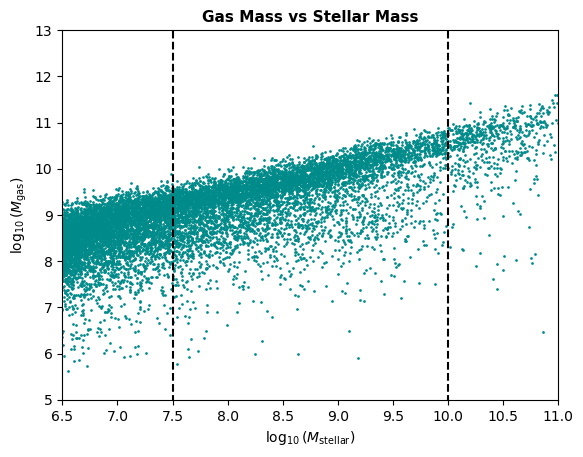

In [4]:
plt.ylim(5,13) 
plt.xlim(6.5,11)
plt.vlines((7.5),0,20,colors = 'k',linestyle = '--')
plt.vlines((10),0,20, colors = 'k',linestyle = '--')
plt.ylabel(r'$\log_{10}(M_{\rm gas})$')
plt.xlabel(r'$\log_{10}(M_{\rm stellar})$')

plt.scatter(np.log10(Mstarsubhalo_TNG50),np.log10(Mgassubhalo_TNG50),s=0.9,c='darkcyan')
plt.title('Gas Mass vs Stellar Mass', fontsize=11, fontweight='bold')
plt.savefig('/home/tnguser/Lucas/images/TNG50-2_GasMassvsStellarMass')

In [17]:
Mstarsubhalo2_TNG50 = []
Metallicity2_TNG50 = []

minmass= 7.5
maxmass= 10

for n in range(subhalos_TNG50['count']):
    if (np.log10(Mstarsubhalo_TNG50[n]) > minmass) & (np.log10(Mstarsubhalo_TNG50[n]) < maxmass):
        Mstarsubhalo2_TNG50.append(Mstarsubhalo_TNG50)
        Metallicity2_TNG50.append(Metallicity_TNG50)
len(Mstarsubhalo2_TNG50)        

/tmp/ipykernel_1302/3264503472.py:8: RuntimeWarning: divide by zero encountered in log10
  if (np.log10(Mstarsubhalo_TNG50[n]) > minmass) & (np.log10(Mstarsubhalo_TNG50[n]) < maxmass):


8740

/tmp/ipykernel_1302/2494816947.py:7: RuntimeWarning: divide by zero encountered in log10
  plt.scatter(np.log10(Mstarsubhalo_TNG50),np.log10(Metallicity_TNG50), s = 0.9, c='darkcyan')


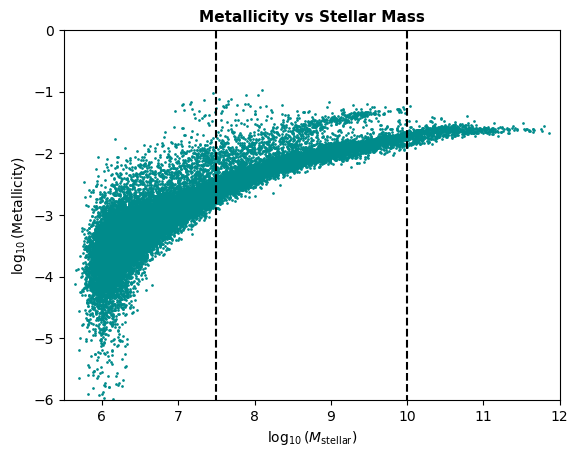

In [18]:
plt.ylabel("$\log_{10}$(Metallicity)")
plt.xlabel(r'$\log_{10}(M_{\rm stellar})$')
plt.xlim(5.5,12) 
plt.ylim(-6,0)
plt.vlines(7.5,-8,0,colors= 'k',linestyle ='--')
plt.vlines(10,-8,0, colors = 'k',linestyle = '--')
plt.scatter(np.log10(Mstarsubhalo_TNG50),np.log10(Metallicity_TNG50), s = 0.9, c='darkcyan')
#plt.scatter(9.43,np.log10(0.12),s=80,color='red',marker='x')
plt.title('Metallicity vs Stellar Mass', fontsize=11, fontweight='bold')
plt.savefig('/home/tnguser/Lucas/images/TNG50-2_MetallicityVsStellarMass')

In [19]:
SFR_TNG50.shape
len(SFR_TNG50)

#SFR = np.zeros_like(SFR_TNG50)

SFR2 = np.array([10**-10 if el == 0 else el for el in SFR_TNG50])
SFRinRad2 = np.array([10**-10 if el == 0 else el for el in SFRinRad_TNG50])
SFRinHalfRad2 = np.array([10**-10 if el == 0 else el for el in SFRinHalfRad_TNG50])


'''
for n in range(len(SFR_TNG50)):
    if SFR_TNG50[n] == 0:
        SFR2[n] = 10**-10
    else:
        SFR2[n] = SFR_TNG50[n]
'''

'\nfor n in range(len(SFR_TNG50)):\n    if SFR_TNG50[n] == 0:\n        SFR2[n] = 10**-10\n    else:\n        SFR2[n] = SFR_TNG50[n]\n'

In [20]:
SFR2.shape

(859077,)

/tmp/ipykernel_1302/1181331069.py:1: RuntimeWarning: divide by zero encountered in log10
  colors = np.log10(Metallicity_TNG50)
/tmp/ipykernel_1302/1181331069.py:6: RuntimeWarning: divide by zero encountered in log10
  plt.scatter(np.log10(Mstarsubhalo_TNG50),np.log10(SFR2),s = 1,c = colors,cmap = 'inferno')


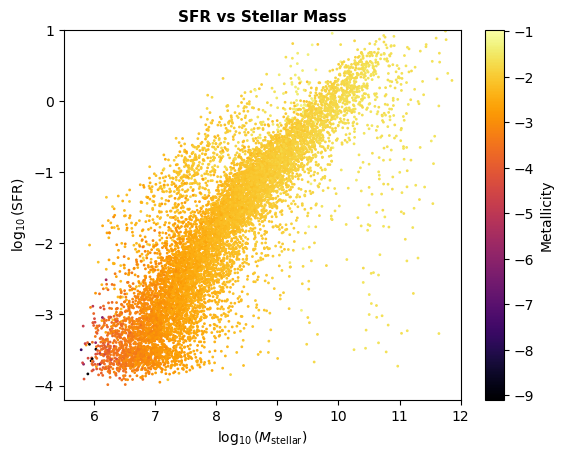

In [21]:
colors = np.log10(Metallicity_TNG50)
plt.xlabel(r'$\log_{10}(M_{\rm stellar})$')
plt.ylabel("$\log_{10}$(SFR)")
plt.xlim(5.5,12) 
plt.ylim(-4.2,1)
plt.scatter(np.log10(Mstarsubhalo_TNG50),np.log10(SFR2),s = 1,c = colors,cmap = 'inferno')
plt.colorbar(label='Metallicity')
plt.title('SFR vs Stellar Mass', fontsize=11, fontweight='bold')
plt.savefig('/home/tnguser/Lucas/images/TNG50-2_SFRVsStellarMassWithMetallicity')

/tmp/ipykernel_1302/1520736406.py:1: RuntimeWarning: divide by zero encountered in log10
  colors = np.log10(Metallicity_TNG50)
/tmp/ipykernel_1302/1520736406.py:6: RuntimeWarning: divide by zero encountered in log10
  plt.scatter(np.log10(Mstarsubhalo_TNG50),np.log10(SFRinRad2),s = 1,c = colors,cmap = 'inferno')


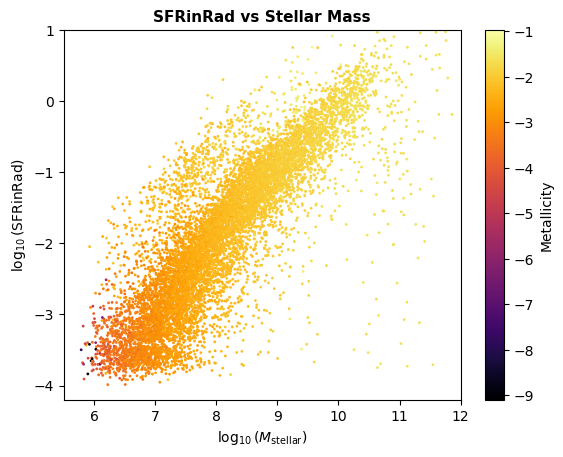

In [22]:
colors = np.log10(Metallicity_TNG50)
plt.xlabel(r'$\log_{10}(M_{\rm stellar})$')
plt.ylabel("$\log_{10}$(SFRinRad)")
plt.xlim(5.5,12) 
plt.ylim(-4.2,1)
plt.scatter(np.log10(Mstarsubhalo_TNG50),np.log10(SFRinRad2),s = 1,c = colors,cmap = 'inferno')
plt.colorbar(label='Metallicity')
plt.title('SFRinRad vs Stellar Mass', fontsize=11, fontweight='bold')
plt.savefig('/home/tnguser/Lucas/images/TNG50-2_SFRinRadVsStellarMassWithMetallicity')

/tmp/ipykernel_1302/256536507.py:1: RuntimeWarning: divide by zero encountered in log10
  colors = np.log10(Metallicity_TNG50)
/tmp/ipykernel_1302/256536507.py:6: RuntimeWarning: divide by zero encountered in log10
  plt.scatter(np.log10(Mstarsubhalo_TNG50),np.log10(SFRinHalfRad2),s = 1,c = colors,cmap = 'inferno')


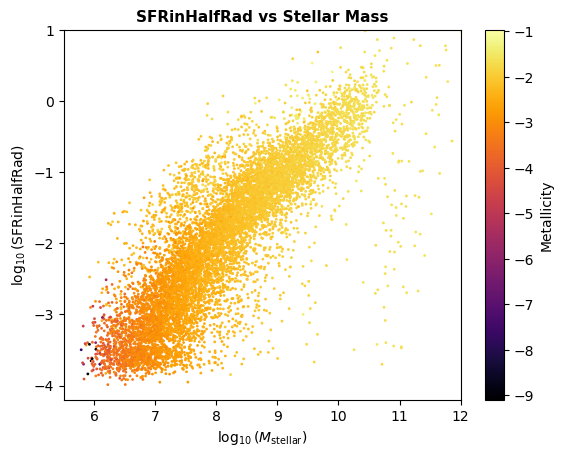

In [24]:
colors = np.log10(Metallicity_TNG50)
plt.xlabel(r'$\log_{10}(M_{\rm stellar})$')
plt.ylabel("$\log_{10}$(SFRinHalfRad)")
plt.xlim(5.5,12) 
plt.ylim(-4.2,1)
plt.scatter(np.log10(Mstarsubhalo_TNG50),np.log10(SFRinHalfRad2),s = 1,c = colors,cmap = 'inferno')
#plt.scatter(9.43,np.log10(0.2),s=80,color='red',marker='x')
plt.colorbar(label='Metallicity')
plt.title('SFRinHalfRad vs Stellar Mass', fontsize=11, fontweight='bold')
plt.savefig('/home/tnguser/Lucas/images/TNG50-2_SFRinHalfRadVsStellarMassWithMetallicity')

In [25]:
sSFR = np.array([SFR2[n]/Mstarsubhalo_TNG50[n] for n in range(len(SFR2))])

/tmp/ipykernel_1302/298100842.py:1: RuntimeWarning: divide by zero encountered in scalar divide
  sSFR = np.array([SFR2[n]/Mstarsubhalo_TNG50[n] for n in range(len(SFR2))])


/tmp/ipykernel_1302/2546049184.py:1: RuntimeWarning: divide by zero encountered in log10
  colors = np.log10(Metallicity_TNG50)
/tmp/ipykernel_1302/2546049184.py:7: RuntimeWarning: divide by zero encountered in log10
  plt.scatter(np.log10(Mstarsubhalo_TNG50),np.log10(sSFR),s = 1,c = colors,cmap = 'inferno')


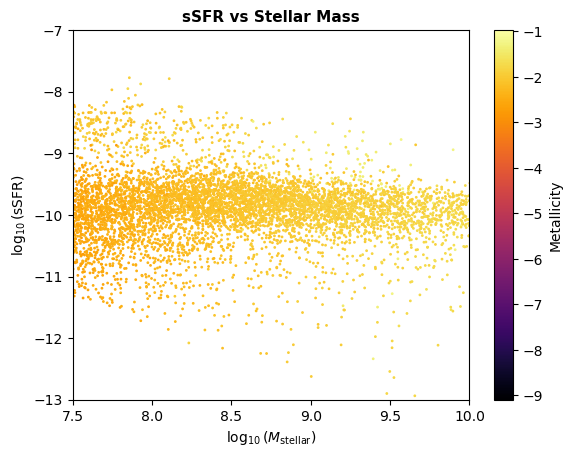

In [35]:
colors = np.log10(Metallicity_TNG50)
plt.xlabel(r'$\log_{10}(M_{\rm stellar})$')
plt.ylabel("$\log_{10}$(sSFR)")
plt.xlim(7.5,10) 
plt.ylim(-13,-7)

plt.scatter(np.log10(Mstarsubhalo_TNG50),np.log10(sSFR),s = 1,c = colors,cmap = 'inferno')
#plt.scatter(9.43,np.log10(0.01),s=80,color='red',marker='x')
plt.colorbar(label='Metallicity')
plt.title('sSFR vs Stellar Mass', fontsize=11, fontweight='bold')
plt.savefig('/home/tnguser/Lucas/images/TNG50-2_sSFRinHalfRadVsStellarMassWithMetallicity')

/tmp/ipykernel_949/3604163821.py:1: RuntimeWarning: divide by zero encountered in log10
  colors = np.log10(Metallicity_TNG50)
/tmp/ipykernel_949/3604163821.py:7: RuntimeWarning: divide by zero encountered in log10
  plt.scatter(np.log10(Mstarsubhalo_TNG50),np.log10(sSFR),s = 1,c = colors,cmap = 'inferno')


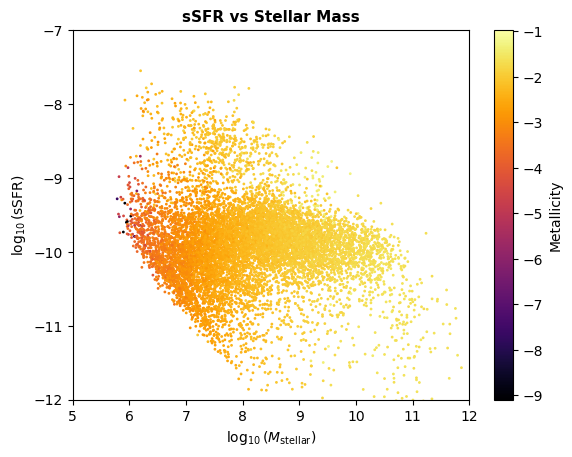

In [20]:
colors = np.log10(Metallicity_TNG50)
plt.xlabel(r'$\log_{10}(M_{\rm stellar})$')
plt.ylabel("$\log_{10}$(sSFR)")
plt.xlim(5,12) 
plt.ylim(-12,-7)

plt.scatter(np.log10(Mstarsubhalo_TNG50),np.log10(sSFR),s = 1,c = colors,cmap = 'inferno')
plt.colorbar(label='Metallicity')
plt.title('sSFR vs Stellar Mass', fontsize=11, fontweight='bold')
plt.savefig('/home/tnguser/Lucas/images/TNG50-2_sSFRVsStellarMassWithMetallicityDwarfs')

In [37]:
SFE = np.array([SFR_TNG50[n]/Mgassubhalo_TNG50[n] for n in range(len(SFR_TNG50))])*1e9

/tmp/ipykernel_1302/3298571810.py:1: RuntimeWarning: invalid value encountered in scalar divide
  SFE = np.array([SFR_TNG50[n]/Mgassubhalo_TNG50[n] for n in range(len(SFR_TNG50))])*1e9


/tmp/ipykernel_1302/3802609665.py:1: RuntimeWarning: divide by zero encountered in log10
  colors = np.log10(Metallicity_TNG50)
/tmp/ipykernel_1302/3802609665.py:7: RuntimeWarning: divide by zero encountered in log10
  plt.scatter(np.log10(Mstarsubhalo_TNG50),np.log10(SFE),s = 1,c = colors,cmap = 'inferno')


Text(0.5, 1.0, 'SFE vs Stellar Mass')

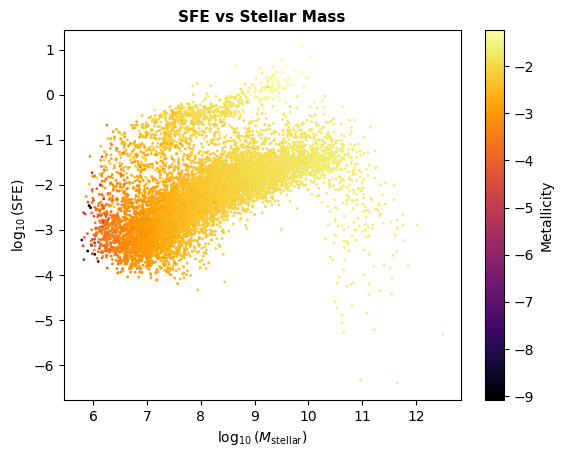

In [38]:
colors = np.log10(Metallicity_TNG50)
plt.xlabel(r'$\log_{10}(M_{\rm stellar})$')
plt.ylabel("$\log_{10}$(SFE)")
#plt.xlim(5,12) 
#plt.ylim(-13,-8.5)

plt.scatter(np.log10(Mstarsubhalo_TNG50),np.log10(SFE),s = 1,c = colors,cmap = 'inferno')
#plt.scatter(9.43,np.log10(0.01),s=80,color='red',marker='x')
plt.colorbar(label='Metallicity')
plt.title('SFE vs Stellar Mass', fontsize=11, fontweight='bold')